<a href="https://colab.research.google.com/github/keyvanmahmoudi/Deep_Learning_Course/blob/main/solutions/Session03_pytorch_fundamentals_solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# پاسخ تمرین‌های جلسهٔ ۳: مبانی PyTorch: تنسور، Autograd و GPU

این نوت‌بوک پاسخ پیشنهادی تمرین‌های انتهای [نوت‌بوک جلسه](../sessions/Session03_pytorch_fundamentals.ipynb) است. قبل از دیدن پاسخ‌ها، خودتان تمرین‌ها را حل کنید؛ معمولاً بیش از یک راه‌حل درست وجود دارد.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### آماده‌سازی

</div>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

_ = torch.manual_seed(42)

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۱

یک دسته ۱۶تایی تصویر رنگی ۶۴×۶۴ با شکل `(16, 64, 64, 3)` بسازید و آن را به شکل مورد انتظار PyTorch یعنی `(16, 3, 64, 64)` تبدیل کنید. سپس میانگین هر کانال رنگی را روی کل دسته حساب کنید (خروجی باید ۳ عدد باشد).

</div>

In [2]:
batch = torch.rand(16, 64, 64, 3)                   # (N, H, W, C) as images usually come from PIL / NumPy
batch_chw = batch.permute(0, 3, 1, 2)               # (N, C, H, W) as PyTorch expects
print('shape:', tuple(batch.shape), '->', tuple(batch_chw.shape))
channel_means = batch_chw.mean(dim=(0, 2, 3))       # average over batch, height and width
print('mean of each colour channel:', channel_means)

shape: (16, 64, 64, 3) -> (16, 3, 64, 64)
mean of each colour channel: tensor([0.4998, 0.5023, 0.5000])


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

`permute(0, 3, 1, 2)` بعد کانال را از آخر به جایگاه دوم می‌برد. برای میانگین هر کانال، روی همهٔ ابعاد **به جز** بعد کانال (یعنی ابعاد ۰، ۲ و ۳) میانگین می‌گیریم. همین محاسبه برای به دست آوردن میانگین و انحراف معیار `Normalize` روی یک دیتاست تصویری استفاده می‌شود.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۲

با autograd مشتق تابع $f(x) = \sin(x)\,e^{-x^2}$ را در ۱۰۰ نقطه حساب کنید و با مشتق تحلیلی مقایسه کنید. (راهنمایی: `f(x).sum().backward()`.)

</div>

max |autograd - analytic|: 5.960464477539063e-08


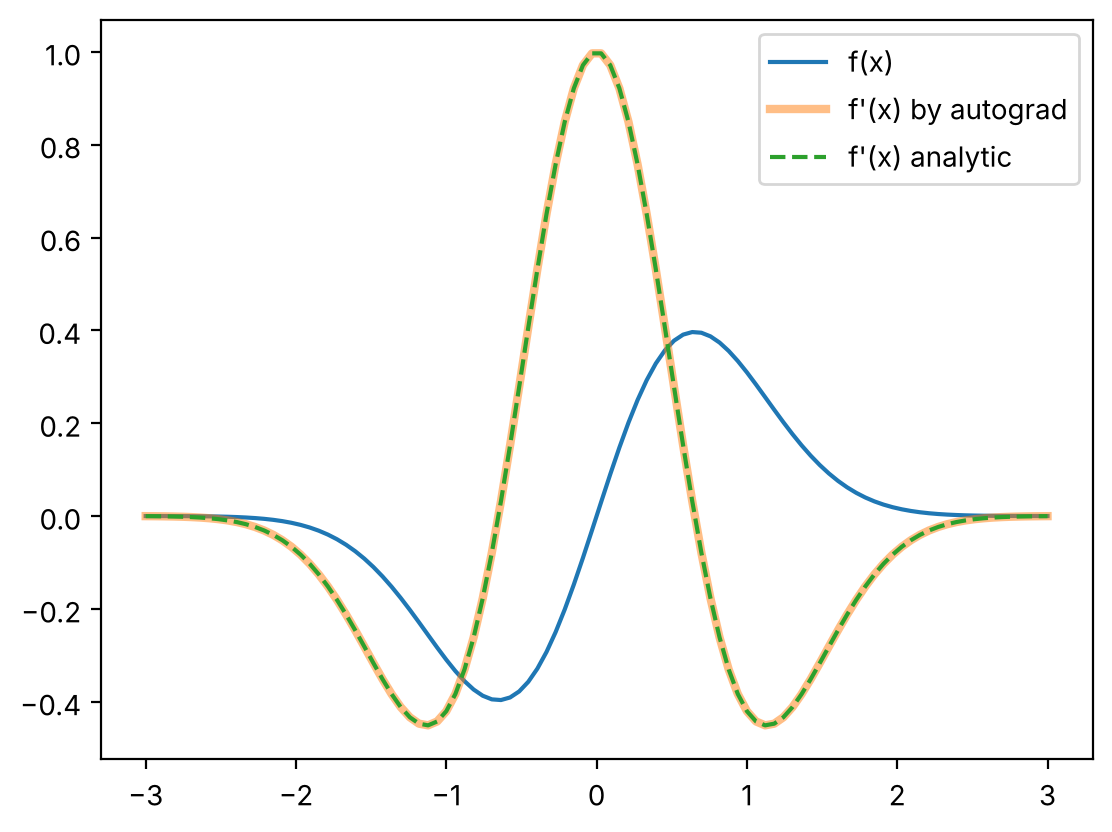

In [3]:
x = torch.linspace(-3, 3, 100, requires_grad=True)
f = torch.sin(x) * torch.exp(-x ** 2)
f.sum().backward()                                  # the sum lets every point get its own derivative

with torch.no_grad():
    analytic = torch.cos(x) * torch.exp(-x ** 2) - 2 * x * torch.sin(x) * torch.exp(-x ** 2)
print('max |autograd - analytic|:', (x.grad - analytic).abs().max().item())

plt.plot(x.detach(), f.detach(), label='f(x)')
plt.plot(x.detach(), x.grad, label="f'(x) by autograd", lw=3, alpha=0.5)
plt.plot(x.detach(), analytic, '--', label="f'(x) analytic")
plt.legend(); plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

`backward` فقط روی یک اسکالر قابل صدا زدن است. چون $f(x_i)$ هر نقطه فقط به همان $x_i$ وابسته است، مشتق $\sum_i f(x_i)$ نسبت به $x_i$ دقیقاً $f'(x_i)$ است؛ پس با یک `backward` مشتق در همهٔ ۱۰۰ نقطه به دست می‌آید. اختلاف با فرمول تحلیلی در حد خطای ممیز شناور است.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۳

در نسخه ۱ رگرسیون خطی، خط `w.grad.zero_()` را حذف کنید. چه اتفاقی می‌افتد و چرا؟

</div>

zero_grad=True : w =      2.983, b =     -1.982, final loss = 1.533e-01


zero_grad=False: w =      5.451, b =     -1.528, final loss = 3.726e+00


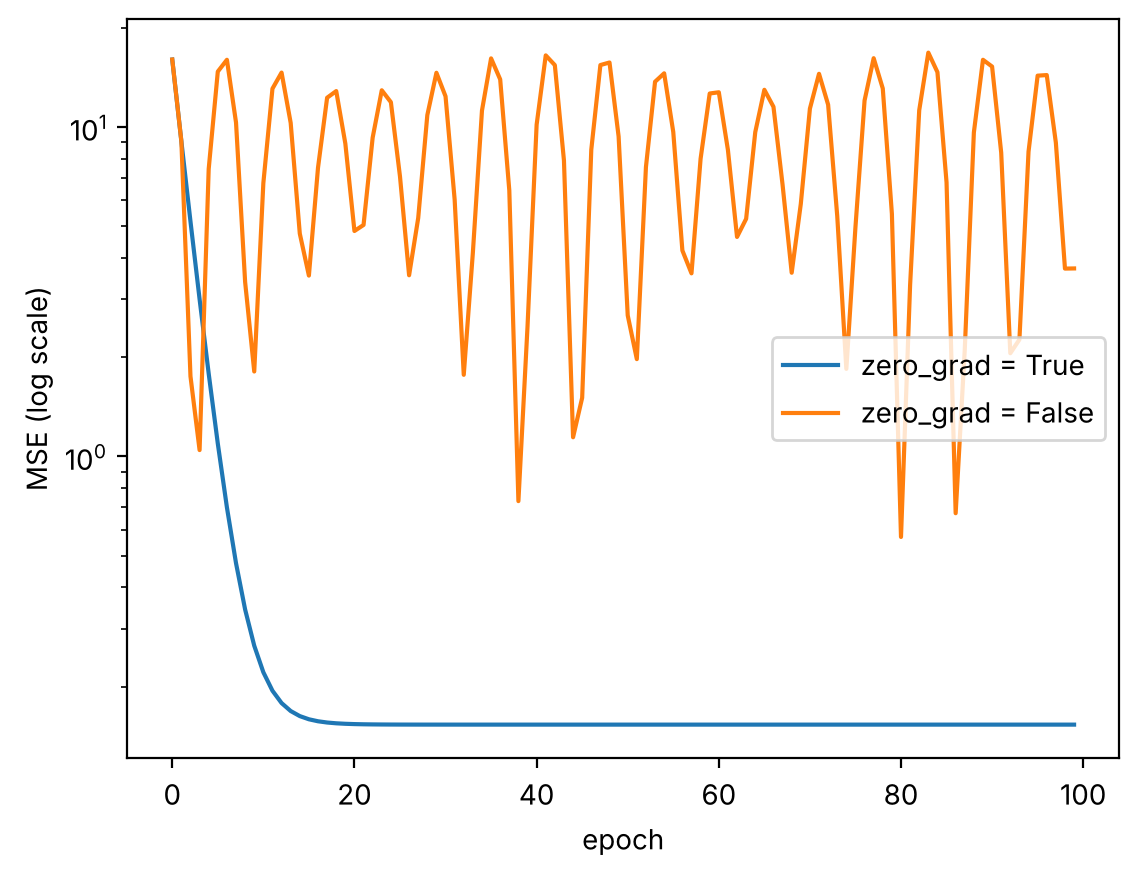

In [4]:
torch.manual_seed(42)
x = torch.linspace(-2, 2, 200).unsqueeze(1)
y = 3 * x - 2 + 0.4 * torch.randn_like(x)


def fit(zero_grad, epochs=100, lr=0.1):
    w = torch.zeros(1, requires_grad=True)
    b = torch.zeros(1, requires_grad=True)
    losses = []
    for _ in range(epochs):
        loss = ((x * w + b - y) ** 2).mean()
        loss.backward()
        with torch.no_grad():
            w -= lr * w.grad
            b -= lr * b.grad
        if zero_grad:
            w.grad.zero_()
            b.grad.zero_()
        losses.append(loss.item())
    return losses, w.item(), b.item()


for zero_grad in (True, False):
    losses, w, b = fit(zero_grad)
    print(f'zero_grad={zero_grad!s:5}: w = {w:10.3f}, b = {b:10.3f}, final loss = {losses[-1]:.3e}')
    plt.semilogy(losses, label=f'zero_grad = {zero_grad}')
plt.xlabel('epoch'); plt.ylabel('MSE (log scale)'); plt.legend(); plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

بدون صفر کردن، گرادیان هر گام با **مجموع** گرادیان‌های همهٔ گام‌های قبلی جمع می‌شود. این مثل Momentum بدون ضریب کاهش است: قدم‌ها مدام بزرگ‌تر می‌شوند، پارامترها از کمینه رد می‌شوند و نوسان می‌کنند یا واگرا می‌شوند. به همین دلیل `optimizer.zero_grad()` بخش جدانشدنی هر حلقهٔ آموزش است.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۴

مدل رگرسیون را برای داده $y = 0.5x^3 - x + \text{noise}$ آموزش دهید. یک بار با `nn.Linear(1, 1)` و یک بار با ویژگی‌های `[x, x², x³]` و `nn.Linear(3, 1)`. نتیجه را مقایسه کنید.

</div>

nn.Linear(1, 1) with x         : MSE = 1.501


nn.Linear(3, 1) with [x, x², x³]: MSE = 0.078
learned weights for [x, x², x³]: [[-1.01 -0.    0.5 ]] bias 0.01


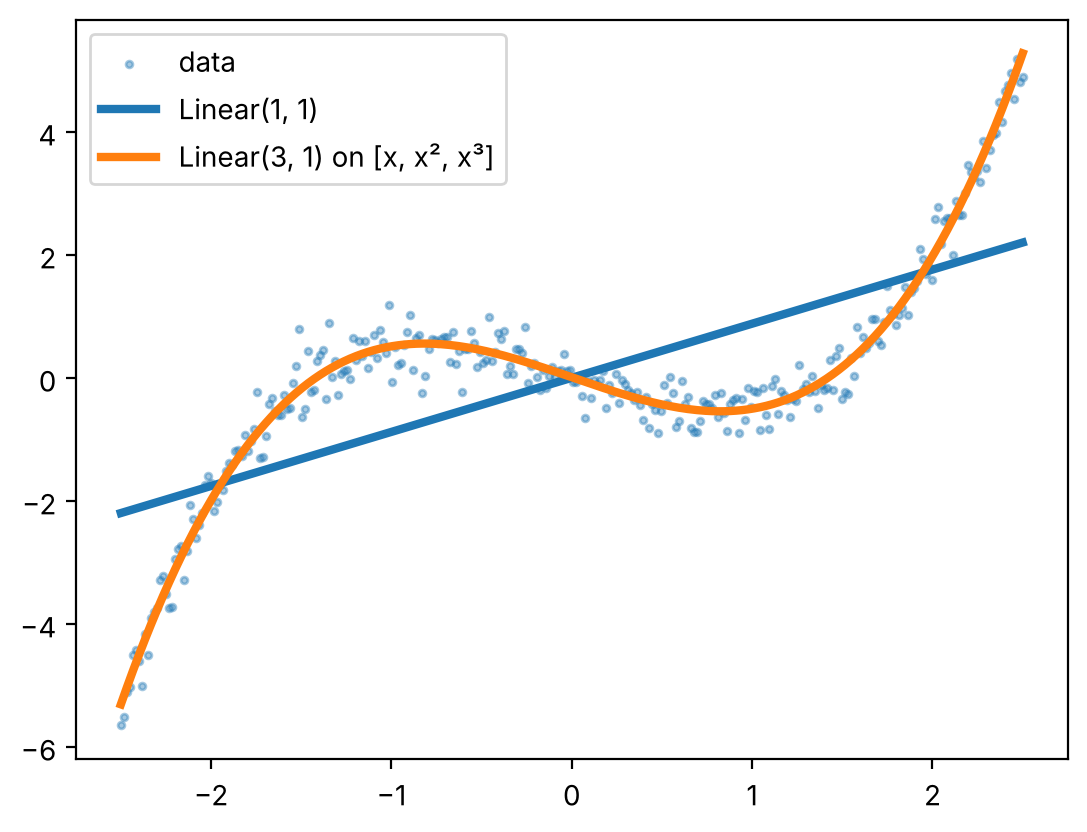

In [5]:
torch.manual_seed(0)
x = torch.linspace(-2.5, 2.5, 300).unsqueeze(1)
y = 0.5 * x ** 3 - x + 0.3 * torch.randn_like(x)


def train(model, inputs, epochs=2000, lr=0.01):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(epochs):
        loss = nn.functional.mse_loss(model(inputs), y)
        opt.zero_grad(); loss.backward(); opt.step()
    return loss.item()


features = torch.cat([x, x ** 2, x ** 3], dim=1)
linear, cubic = nn.Linear(1, 1), nn.Linear(3, 1)
print(f'nn.Linear(1, 1) with x         : MSE = {train(linear, x):.3f}')
print(f'nn.Linear(3, 1) with [x, x², x³]: MSE = {train(cubic, features):.3f}')
print('learned weights for [x, x², x³]:', cubic.weight.data.numpy().round(2), 'bias', round(cubic.bias.item(), 2))

with torch.no_grad():
    plt.scatter(x, y, s=6, alpha=0.4, label='data')
    plt.plot(x, linear(x), lw=3, label='Linear(1, 1)')
    plt.plot(x, cubic(features), lw=3, label='Linear(3, 1) on [x, x², x³]')
plt.legend(); plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

یک خط راست نمی‌تواند رابطهٔ درجهٔ سه را مدل کند و خطایش زیاد می‌ماند (Underfitting). با ویژگی‌های چندجمله‌ای، همان مدل خطی ضرایب واقعی (نزدیک ۰٫۵، صفر و ۱−) را پیدا می‌کند و خطا تا سطح نویز پایین می‌آید. این همان رگرسیون چندجمله‌ای دورهٔ یادگیری ماشین است: **ما** ویژگی‌ها را طراحی کردیم. شبکهٔ عصبی با لایه‌های پنهان، چنین ویژگی‌هایی را **خودش یاد می‌گیرد**؛ مثلاً یک `nn.Sequential(nn.Linear(1, 32), nn.ReLU(), nn.Linear(32, 1))` را امتحان کنید.

</div>